# Figure S5: sea surface salinity change during the collapsed period, 8xCO2

Mean surface salinity over years 2250-2349 minus years 750-849, on the native POP grid.

Input: `SSS_mean_change_800_2300_8x.nc`. `pop_tools` downloads the POP grid and cartopy downloads coastlines on first use.

In [1]:
import numpy as np
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import common
import warnings
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean as cm
with warnings.catch_warnings():
    warnings.simplefilter('ignore', UserWarning)  # pop_tools warns about pkg_resources when imported
    import pop_tools

matplotlib.rc('font', size=14)

In [2]:
fields = xr.open_dataset(common.data_path('SSS_mean_change_800_2300_8x.nc'))
sss_change = (fields.SSS_end - fields.SSS_start).values

grid = pop_tools.get_grid('POP_gx1v6')
# Atlantic, Labrador Sea, GIN Seas, Arctic and Hudson Bay; no Mediterranean, Baltic or Black Sea
keep = np.isin(grid.REGION_MASK.values, [6, 8, 9, 10, 11])

# T-cell corners are the U points, periodic in longitude; the first T row has no corners below it, so it is dropped
ulon = ((grid.ULONG.values + 180) % 360) - 180
lon_corners = np.concatenate([ulon[:, -1:], ulon], axis=1)
lat_corners = np.concatenate([grid.ULAT.values[:, -1:], grid.ULAT.values], axis=1)
# Cells that cross the date line would smear across the map, so they are masked
wraps = (np.abs(np.diff(lon_corners, axis=1))[1:, :] > 180) | (np.abs(np.diff(lon_corners, axis=0))[:, 1:] > 180)

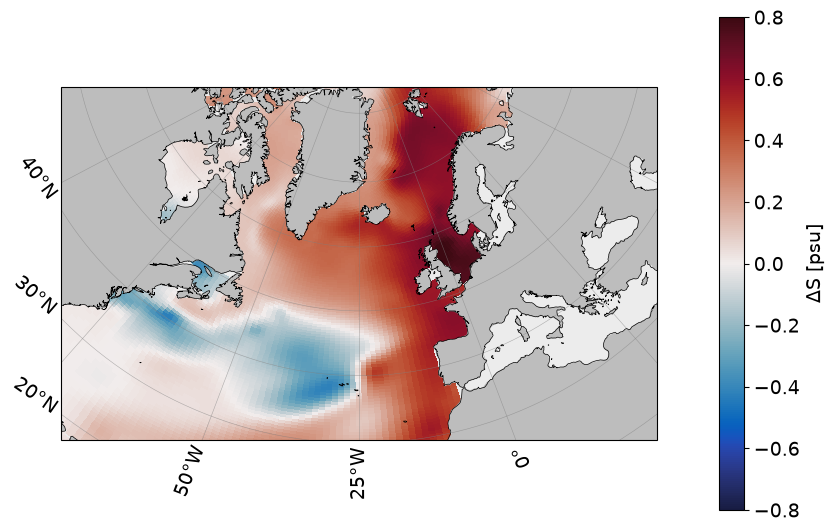

In [3]:
projection = ccrs.LambertConformal(central_longitude=-25, central_latitude=55, standard_parallels=(40, 70))
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': projection})

values = np.ma.masked_where(wraps | ~keep[1:, :] | ~np.isfinite(sss_change[1:, :]), sss_change[1:, :])
p = ax.pcolormesh(lon_corners, lat_corners, values, vmin=-0.8, vmax=0.8, cmap=cm.cm.balance,
                  transform=ccrs.PlateCarree(), shading='flat')
ax.add_feature(cfeature.LAND, facecolor='#bdbdbd', zorder=2)
ax.set_facecolor('#ececec')  # masked seas are light gray, land is darker
ax.coastlines(resolution='50m', linewidth=0.5, zorder=3)
ax.set_extent((-80, 30, 30, 80), crs=ccrs.PlateCarree())
gridlines = ax.gridlines(draw_labels=True, linewidth=0.4, color='grey', alpha=0.6, x_inline=False, y_inline=False)
gridlines.top_labels = gridlines.right_labels = False
plt.colorbar(p, ax=ax, label='ΔS [psu]', shrink=0.8, pad=0.08)
plt.savefig(common.figure_path('figS5_sss_change.png'), dpi=150, bbox_inches='tight')
plt.show()